Connected to Python 3.13.2

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn import datasets
from sklearn.preprocessing import OneHotEncoder
import numpy as np
import pandas as pd


iris = datasets.load_iris()
X = iris.data  # shape (150, 4)
y = iris.target.reshape(-1, 1)  # shape (150, 1)

# 2. One-hot encoding (catgorial)
encoder = OneHotEncoder(sparse_output=False)
Y = encoder.fit_transform(y)  # shape (150, 3)

# 3. train test split
X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.2, stratify=y, random_state=42
)

# 4. standardized feature
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

In [ ]:
#define NN
class NN():
    def __init__(self, input_size , hidden_size , output_size,seed = None):
        self.input_size= input_size
        self.hidden_size= hidden_size
        self. output_size=  output_size
        if seed is not None:
            np.random.seed(seed)
        
        # initialize weights for input to hidden layer use sigmoid so xaviar initialization
        self.weights_input_hidden = np.random.randn(self.input_size , self.hidden_size)*np.sqrt(1.0/self.input_size)#用xavier
        #for hidden to output    
        self.weights_hidden_output = np.random.randn( self.hidden_size, self. output_size  )*np.sqrt(1.0/self.hidden_size)
        #initialize bias for hidden
        self.bias_hidden = np.zeros((1,self.hidden_size))
        #initialize bias for output
        self.bias_output = np.zeros((1,self. output_size))
        #record activ what we use
        self.output_activation_type = None
    
    def sigmoid(self , x):
        return 1/(1+np.exp(-x))   #sigmoid function
    
    def sigmoid_derivative(self , x):
        return x *(1-x)    #導數
    # three dimension to probability softmax
    
    def softmax(self, x):
        exp_x = np.exp(x - np.max(x, axis=1, keepdims=True))
        return exp_x / np.sum(exp_x, axis=1, keepdims=True)
    #cross entropy loss
    
    def compute_loss_ce(self, Y_true, Y_pred):
        m = Y_true.shape[0]
        return -np.sum(Y_true * np.log(Y_pred + 1e-8)) / m
    def compute_loss_mse(self, Y_true, Y_pred):
        return np.mean((Y_true - Y_pred) ** 2)
    
    
    
    
    #define feedforward
    def feedforward(self, X,output_activation='softmax'):
        #calculateactivation
        self.hidden_activation = np.dot(X,self.weights_input_hidden)+ self.bias_hidden
        #給activate function 給hidden
        self.hidden_output= self.sigmoid(self.hidden_activation)
        
        self.output_activation = np.dot(self.hidden_output, self.weights_hidden_output) + self.bias_output
        
        
        
        #define
        
        if output_activation == 'softmax':
            self.predicted_output = self.softmax(self.output_activation)
        else:
            raise ValueError("output_activation must be 'sigmoid', 'linear', or 'softmax'")
        
        return self.predicted_output

    #definr backward
    def backward(self, X, y, learning_rate):
        m = X.shape[0]
        # 輸出層誤差 /m 梯度標準化
        
        output_delta = (self.predicted_output - y) / m  # CE 對 softmax 的梯度
     
       
        #gardient descent use minus difference
        #caculate the error and delta at hidden
        hidden_error = np.dot(output_delta, self.weights_hidden_output.T)
        hidden_delta = hidden_error * self.sigmoid_derivative(self.hidden_output)
        #update hidden w
        self.weights_hidden_output -= np.dot(self.hidden_output.T,output_delta) * learning_rate
        self.bias_output -= np.sum(output_delta, axis=0,keepdims=True) * learning_rate
        #update input w 
        self.weights_input_hidden -= np.dot(X.T, hidden_delta) * learning_rate
        self.bias_hidden -= np.sum(hidden_delta, axis=0,keepdims=True) * learning_rate #梯度下降

    def train(self, X, Y, epochs=5000, learning_rate=0.1,  log=500, error_loss=None):
        self.history_ = []
        for epoch in range(epochs):
            Y_pred = self.feedforward(X, )
            
            loss = self.compute_loss_ce(Y, Y_pred)
            
            self.history_.append(loss)   #record loss

            self.backward(X, Y, learning_rate, )

            if epoch % log == 0:
                print(f"Eppoch {epoch},Loss:{loss}")
            if (error_loss is not None) and (loss < error_loss):
                print(f"Early stopping at epoch {epoch}, Loss: {loss:.6f}")
                break    
            
    def predict(self, X, task='classification'):
        y_hat = self.feedforward(X)
        
            
        return np.argmax(y_hat, axis=1)     

In [ ]:
hidden_sizes   = [8, 12, 16]        # 建議比 2/3/4 大一些
learning_rates = [0.1, 0.05, 0.01]
results = []

for h in hidden_sizes:
    for lr in learning_rates:
        print(f"\nTraining with hidden_size={h}, learning_rate={lr}")
        model = NN(input_size=4, hidden_size=h, output_size=3,seed=42)

        # softmax + cross-entropy 的訓練
        model.train(X_train, Y_train,
                    epochs=5000, learning_rate=lr,
                   
                    log=500)

        # 測試集預測與準確率
        probs   = model.feedforward(X_test)                 # softmax 機率
        y_pred  = np.argmax(probs, axis=1)                 # (n,)
        y_true  = np.argmax(Y_test, axis=1)                # (n,)
        acc     = (y_pred == y_true).mean()

        results.append({
            "hidden_size": h,
            "learning_rate": lr,
            "final_loss": model.history_[-1],
            "test_accuracy": float(acc)
        })


Training with hidden_size=8, learning_rate=0.1
Eppoch 0,Loss:1.1869573683430796
Eppoch 500,Loss:0.2482980316356397
Eppoch 1000,Loss:0.1327313606808212
Eppoch 1500,Loss:0.0936039593794893
Eppoch 2000,Loss:0.07659202710031748
Eppoch 2500,Loss:0.06734776924931675
Eppoch 3000,Loss:0.061559983716704764
Eppoch 3500,Loss:0.05758351723862957
Eppoch 4000,Loss:0.054671980659201376
Eppoch 4500,Loss:0.052440856940326054

Training with hidden_size=8, learning_rate=0.05
Eppoch 0,Loss:1.1869573683430796
Eppoch 500,Loss:0.3800063153924459
Eppoch 1000,Loss:0.2482396597078397
Eppoch 1500,Loss:0.174823700430089
Eppoch 2000,Loss:0.1327178058172486
Eppoch 2500,Loss:0.10855863571506301
Eppoch 3000,Loss:0.09360203430488419
Eppoch 3500,Loss:0.08363760582468363
Eppoch 4000,Loss:0.07659217060731012
Eppoch 4500,Loss:0.07136925631086347

Training with hidden_size=8, learning_rate=0.01
Eppoch 0,Loss:1.1869573683430796
Eppoch 500,Loss:0.8704394098907914
Eppoch 1000,Loss:0.6323058289775285
Eppoch 1500,Loss:0.501320


 超參數測試結果：
   hidden_size  learning_rate  final_loss  test_accuracy
6           16           0.10    0.049316       0.966667
3           12           0.10    0.050412       0.966667
0            8           0.10    0.050675       0.966667
7           16           0.05    0.064153       0.966667
4           12           0.05    0.066535       0.966667
1            8           0.05    0.067355       0.966667
5           12           0.01    0.216943       0.900000
8           16           0.01    0.226297       0.900000
2            8           0.01    0.248230       0.900000


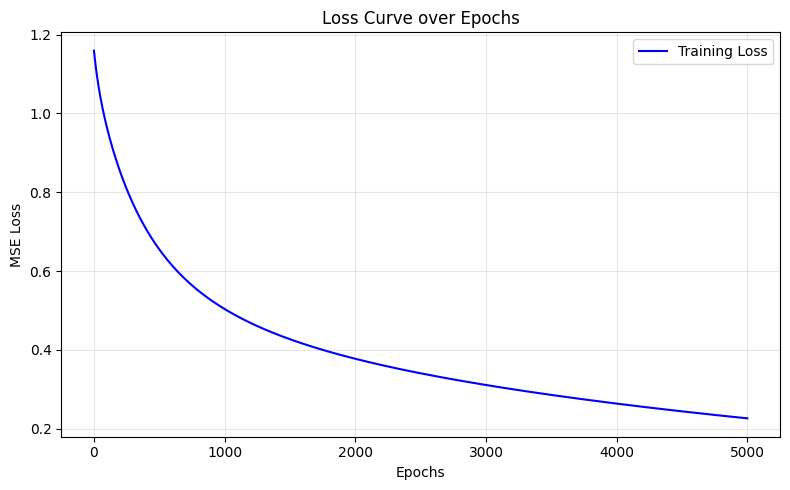

In [ ]:
# 彙整結果
import pandas as pd
import matplotlib.pyplot as plt
df = pd.DataFrame(results)
print("\n 超參數測試結果：")
print(df.sort_values(["test_accuracy", "final_loss"], ascending=[False, True]))

plt.figure(figsize=(8, 5))
plt.plot(model.history_, label="Training Loss", color='blue')
plt.title("Loss Curve over Epochs")
plt.xlabel("Epochs")
plt.ylabel("MSE Loss")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


 hidden_size  learning_rate  final_loss  test_accuracy
          16           0.10    0.049316       0.966667
          12           0.10    0.050412       0.966667
           8           0.10    0.050675       0.966667
          16           0.05    0.064153       0.966667
          12           0.05    0.066535       0.966667
           8           0.05    0.067355       0.966667
          12           0.01    0.216943       0.900000
          16           0.01    0.226297       0.900000
           8           0.01    0.248230       0.900000

🏆 Best Configuration

   Hidden Size: 16
   Learning Rate: 0.1
   Final Loss: 0.049316
   Test Accuracy: 96.67%

🔬 Detailed Analysis - Best Model
Eppoch 0,Loss:1.1592797260837244
Eppoch 5000,Loss:0.0493131357026929

🔍 Test Set Predictions:
     0 | True: 0 | Pred: 0 | MaxProb: 0.9987 | ✅
     1 | True: 2 | Pred: 2 | MaxProb: 0.7591 | ✅
     2 | True: 1 | Pred: 1 | MaxProb: 0.9942 | ✅
     3 | True: 1 | Pred: 1 | MaxProb: 0.9983 | ✅
     4 | Tru

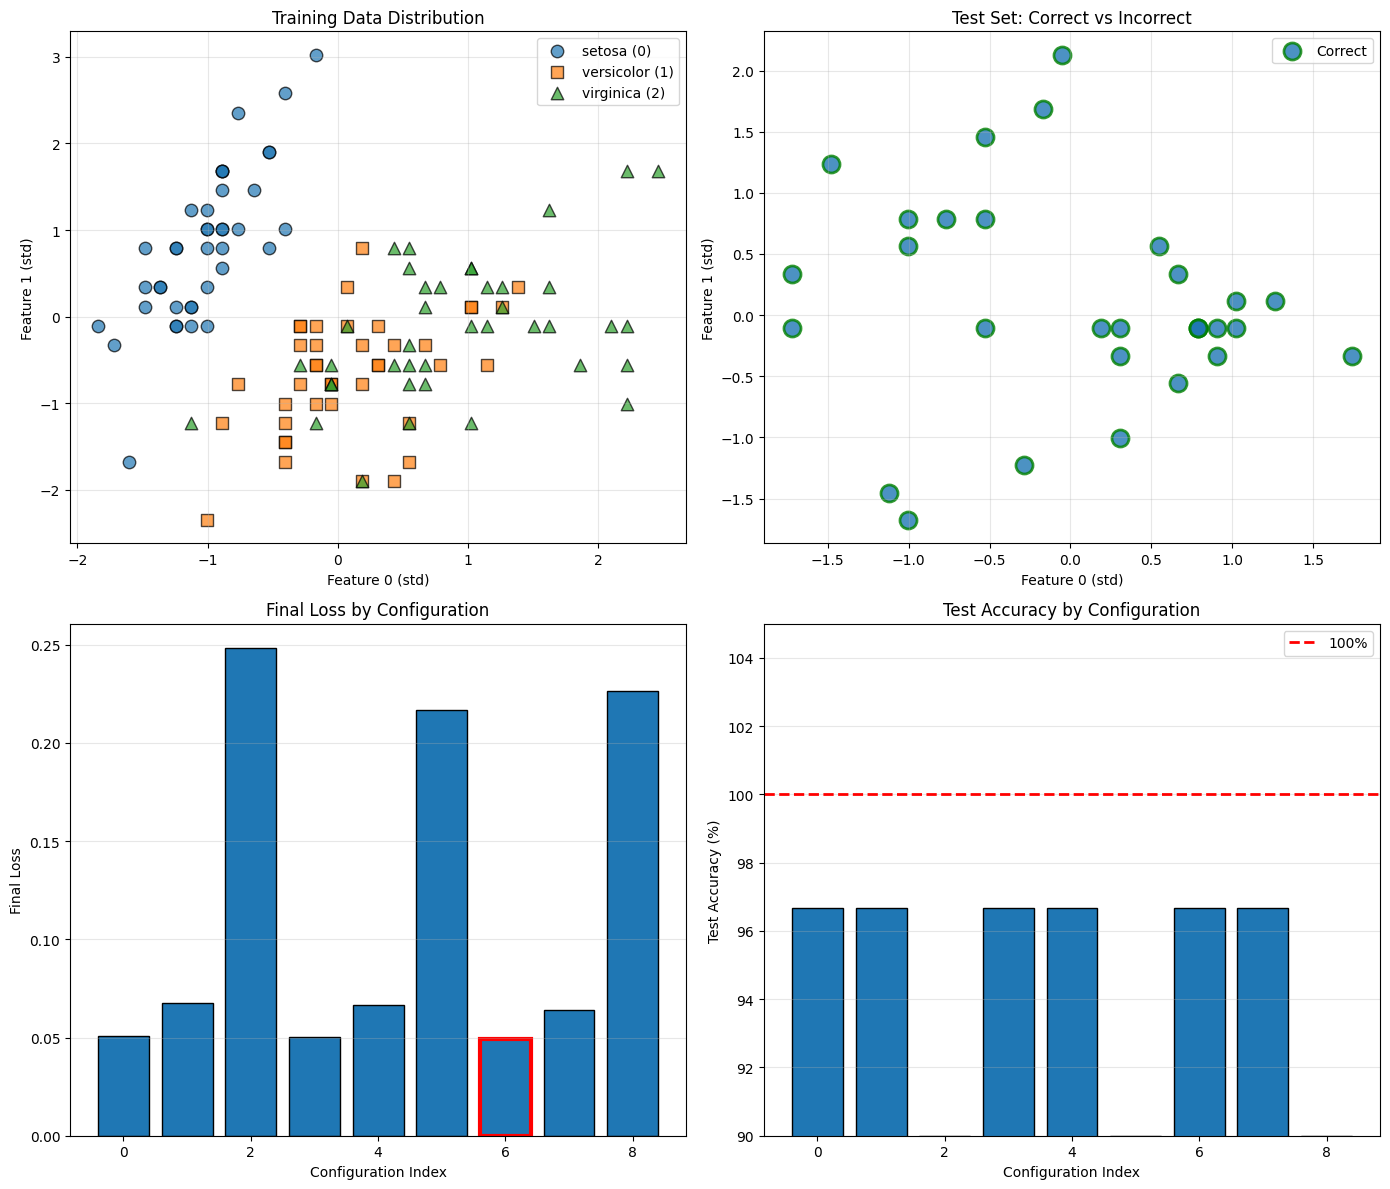


✨ Analysis Complete!


In [ ]:
import matplotlib.pyplot as plt
df = pd.DataFrame(results)
df_sorted = df.sort_values(["test_accuracy", "final_loss"], 
                           ascending=[False, True])
print("\n" + df_sorted.to_string(index=False))
best_idx = df_sorted.index[0]
best_config = df_sorted.iloc[0]
print("\n" + "=" * 70)
print("🏆 Best Configuration")
print("=" * 70)
print(f"\n   Hidden Size: {int(best_config['hidden_size'])}")
print(f"   Learning Rate: {best_config['learning_rate']}")
print(f"   Final Loss: {best_config['final_loss']:.6f}")
print(f"   Test Accuracy: {best_config['test_accuracy']*100:.2f}%")

# ==================== Detailed Analysis of Best Model ====================
print("\n" + "=" * 70)
print("🔬 Detailed Analysis - Best Model")
print("=" * 70)

best_model = NN(input_size=4,
                hidden_size=int(best_config['hidden_size']),
                output_size=3,
                seed=42)
best_model.train(X_train, Y_train, epochs=10000,
                 learning_rate=best_config['learning_rate'],
                 
                 error_loss=0.001, log=5000)

# ===== 測試集評估（多類別）
y_prob_test = best_model.feedforward(X_test)
y_pred_test = np.argmax(y_prob_test, axis=1)       # 預測標籤
y_true_test = np.argmax(Y_test, axis=1)            # 真實標籤

print("\n🔍 Test Set Predictions:")
for i in range(len(X_test)):
    status = "✅" if y_pred_test[i] == y_true_test[i] else "❌"
    print(f"   {i:3d} | True: {y_true_test[i]} | Pred: {y_pred_test[i]} | MaxProb: {y_prob_test[i].max():.4f} | {status}")

correct = np.sum(y_pred_test == y_true_test)
incorrect = len(y_true_test) - correct
print(f"\n📊 Confusion Summary:")
print(f"   Correct: {correct}/{len(y_true_test)} ({correct/len(y_true_test)*100:.1f}%)")
print(f"   Incorrect: {incorrect}/{len(y_true_test)} ({incorrect/len(y_true_test)*100:.1f}%)")

max_probs = y_prob_test.max(axis=1)
print(f"\n🎯 Confidence:")
print(f"   Confident samples (max prob > 0.9): {(max_probs > 0.9).sum()}/{len(max_probs)} ({(max_probs > 0.9).mean()*100:.1f}%)")
print(f"   Mean of max probs: {max_probs.mean():.4f}")

# =========================
#       視覺化
# =========================
print("\n" + "=" * 70)
print("📊 Generating Visualizations...")
print("=" * 70)

fig, axes = plt.subplots(2, 2, figsize=(14, 12))

# (1) 訓練資料分布（取前兩個特徵示意）
ax1 = axes[0, 0]
y_train_lbl = np.argmax(Y_train, axis=1)
for cls, name, marker in zip([0,1,2], iris.target_names, ['o','s','^']):
    mask = (y_train_lbl == cls)
    ax1.scatter(X_train[mask, 0], X_train[mask, 1],
                label=f"{name} ({cls})", alpha=0.7, s=80, edgecolors='black', marker=marker)
ax1.set_xlabel('Feature 0 (std)')
ax1.set_ylabel('Feature 1 (std)')
ax1.set_title('Training Data Distribution')
ax1.legend()
ax1.grid(True, alpha=0.3)

# (2) 測試集：正確/錯誤
ax2 = axes[0, 1]
correct_mask = (y_pred_test == y_true_test)
ax2.scatter(X_test[correct_mask, 0], X_test[correct_mask, 1],
            s=150, marker='o', edgecolors='green', linewidths=2,
            label='Correct', alpha=0.8)
if np.any(~correct_mask):
    ax2.scatter(X_test[~correct_mask, 0], X_test[~correct_mask, 1],
                s=150, marker='X', edgecolors='red', linewidths=2,
                label='Incorrect', alpha=0.9)
ax2.set_xlabel('Feature 0 (std)')
ax2.set_ylabel('Feature 1 (std)')
ax2.set_title('Test Set: Correct vs Incorrect')
ax2.legend()
ax2.grid(True, alpha=0.3)

# (3) 各組合最終 Loss
ax3 = axes[1, 0]
x_pos = np.arange(len(df))
bars = ax3.bar(x_pos, df['final_loss'], edgecolor='black')
ax3.set_xlabel('Configuration Index')
ax3.set_ylabel('Final Loss')
ax3.set_title('Final Loss by Configuration')
ax3.grid(True, alpha=0.3, axis='y')
best_bar_idx = df['final_loss'].idxmin()
bars[list(df.index).index(best_bar_idx)].set_edgecolor('red')
bars[list(df.index).index(best_bar_idx)].set_linewidth(3)

# (4) 各組合 Accuracy
ax4 = axes[1, 1]
accuracy_pct = df['test_accuracy'] * 100
bars = ax4.bar(x_pos, accuracy_pct, edgecolor='black')
ax4.set_xlabel('Configuration Index')
ax4.set_ylabel('Test Accuracy (%)')
ax4.set_title('Test Accuracy by Configuration')
ax4.axhline(y=100, color='red', linestyle='--', linewidth=2, label='100%')
ax4.set_ylim([90, 105])
ax4.legend()
ax4.grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('iris_multiclass_nn_results.png', dpi=300, bbox_inches='tight')
print("✅ Saved visualization to 'iris_multiclass_nn_results.png'")
plt.show()

print("\n" + "=" * 70)
print("✨ Analysis Complete!")
print("=" * 70)